In [ ]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 13.3 MB/s eta 0:00:00


In [ ]:
!pip install torchinfo

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

from torchinfo import summary

from torchvision import datasets
from torchvision import transforms
import torchvision

from torchmetrics import Accuracy, ConfusionMatrix

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import numpy as np
import pandas as pd

import requests

import pathlib
import random
import shutil
from PIL import Image
import os
import math

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
def download_data():
  random.seed(42)
  amount = 0.2
  data_splits = ["train", "test"]
  target_classes = ["pizza", "steak", "sushi"]

  data_dir = pathlib.Path("../data")
  train_data = datasets.Food101(root=data_dir,
                                split="train",
                                download=True)
  test_data = datasets.Food101(root=data_dir,
                              split="test",
                              download=True)

  data_path = data_dir / "food-101" / "images"
  label_splits = {}
  for data_split in data_splits:
      label_path = data_dir / "food-101" / "meta" / f"{data_split}.txt"
      with open(label_path, "r") as f:
          labels = [line.strip("\n") for line in f.readlines() if line.split("/")[0] in target_classes]
      sampled_images = random.sample(labels, k=round(amount * len(labels)))
      label_splits[data_split] = [pathlib.Path(str(data_path / sample_image) + ".jpg") for sample_image in sampled_images]

  target_dir = pathlib.Path(f"../data/pizza_steak_sushi_{str(int(amount*100))}_percent")
  target_dir.mkdir(parents=True, exist_ok=True)
  for image_split in label_splits.keys():
      for image_path in label_splits[str(image_split)]:
          dest_dir = target_dir / image_split / image_path.parent.stem / image_path.name
          dest_dir.parent.mkdir(parents=True, exist_ok=True)
          shutil.copy2(image_path, dest_dir)

download_data()

100%|██████████| 5.00G/5.00G [02:26<00:00, 34.0MB/s]


In [ ]:
data_dir = pathlib.Path(f"../data/pizza_steak_sushi_20_percent")

data_dir.exists()

True

In [ ]:
for dirpath, dirnames, filenames in data_dir.walk():
  if not filenames:
    continue
  print(f"{dirpath}: {len(filenames)}")

image_paths = list(data_dir.glob("**/*.jpg"))
len(image_paths)

../data/pizza_steak_sushi_20_percent/test/pizza: 46
../data/pizza_steak_sushi_20_percent/test/sushi: 46
../data/pizza_steak_sushi_20_percent/test/steak: 58
../data/pizza_steak_sushi_20_percent/train/pizza: 154
../data/pizza_steak_sushi_20_percent/train/sushi: 150
../data/pizza_steak_sushi_20_percent/train/steak: 146


600

In [ ]:
train_dir = data_dir / "train"
test_dir = data_dir / "test"

../data/pizza_steak_sushi_20_percent/train/pizza/2154394.jpg
pizza
512x512


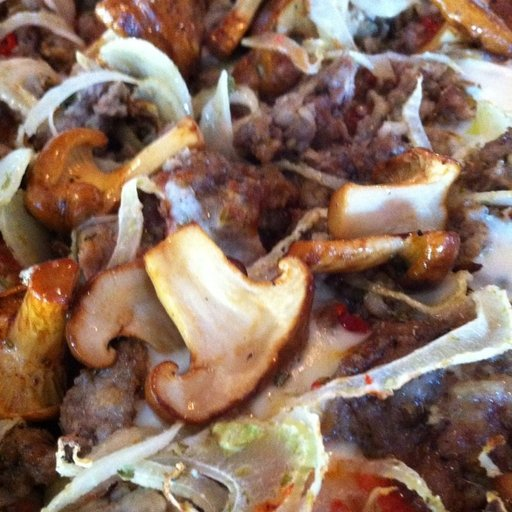

In [ ]:
random.seed(42)

rnd_img = random.choice(image_paths)
print(rnd_img)

img_class = rnd_img.parent.stem
print(img_class)

img_batch = Image.open(rnd_img)
print(f"{img_batch.height}x{img_batch.width}")

img_batch

(512, 512, 3)

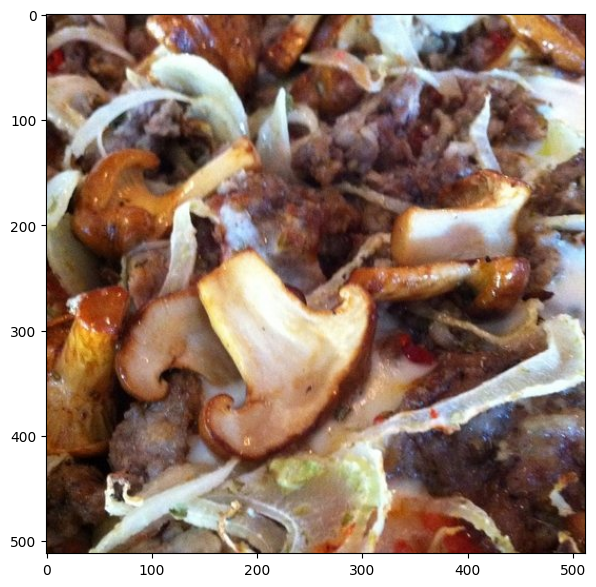

In [ ]:
img_arr = np.asarray(img_batch)
plt.figure(figsize=(10,7))
plt.imshow(img_arr)
img_arr.shape

In [ ]:
data_transform = transforms.Compose([ # nn.Sequential can be used as well
  transforms.Resize(size=(64,64)),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.ToTensor()
])

In [ ]:
tensor = data_transform(img_batch)

tensor.shape, tensor[0][0]

(torch.Size([3, 64, 64]),
 tensor([0.2353, 0.3020, 0.3922, 0.4667, 0.4314, 0.4706, 0.6196, 0.5490, 0.5216,
         0.2431, 0.1490, 0.2824, 0.6627, 0.7216, 0.6549, 0.6588, 0.6157, 0.7451,
         0.6431, 0.5373, 0.5333, 0.4706, 0.5176, 0.5098, 0.3490, 0.2667, 0.3333,
         0.4235, 0.4039, 0.5490, 0.7569, 0.6824, 0.3490, 0.2392, 0.4157, 0.5804,
         0.6471, 0.6118, 0.6863, 0.7882, 0.8235, 0.8588, 0.8627, 0.6824, 0.6549,
         0.7529, 0.7647, 0.7922, 0.8235, 0.7961, 0.7412, 0.5843, 0.5137, 0.4667,
         0.6549, 0.8235, 0.8510, 0.8392, 0.7490, 0.6667, 0.6275, 0.4275, 0.4235,
         0.4196]))

torch.Size([64, 64, 3])

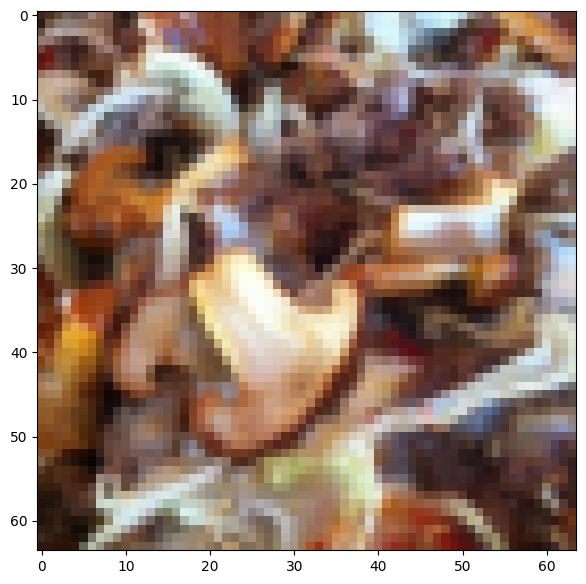

In [ ]:
permuted = tensor.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

permuted.shape

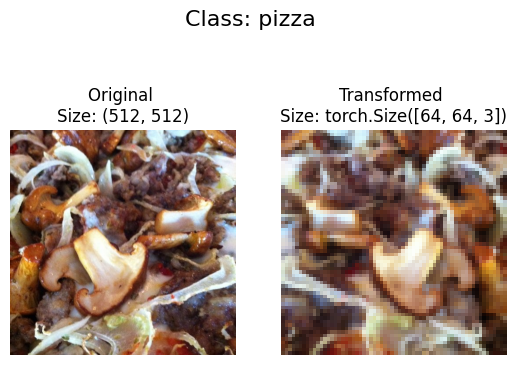

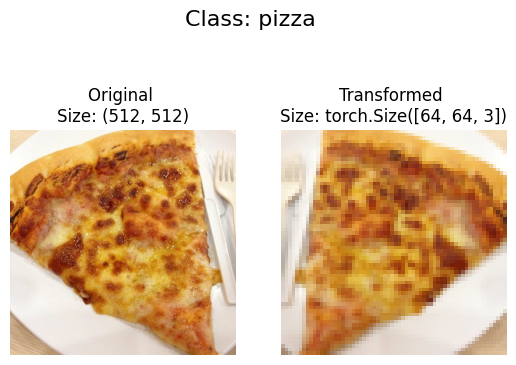

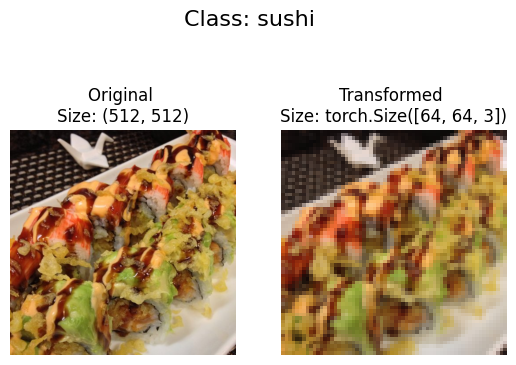

In [ ]:
def plot_transformed_images(image_paths, transform, n=3, seed=42):
  random.seed(seed)
  random_image_paths = random.sample(image_paths, k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(1, 2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original \nSize: {f.size}")
      ax[0].axis("off")

      transformed_image = transform(f).permute(1, 2, 0).cpu()
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
      ax[1].axis("off")

      fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_paths,transform=data_transform,n=3)

In [ ]:
train_data = datasets.ImageFolder(
  root=train_dir,
  transform=data_transform,
  target_transform=None, # label inferred by the folder name
)
test_data = datasets.ImageFolder(
  root=test_dir,
  transform=data_transform,
  target_transform=None, # label inferred by the folder name
)

In [ ]:
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 450
     Root location: ../data/pizza_steak_sushi_20_percent/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 150
     Root location: ../data/pizza_steak_sushi_20_percent/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [ ]:
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [ ]:
len(train_data), len(test_data)

(450, 150)

(torch.Size([3, 64, 64]), torch.Size([64, 64, 3]), 0, 'pizza')

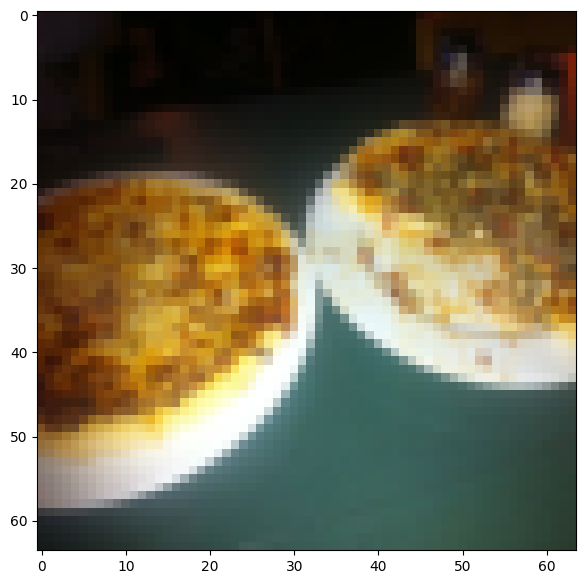

In [ ]:
img_batch, lbl_batch = train_data[0][0], train_data[0][1]
permuted = img_batch.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

img_batch.shape, permuted.shape, lbl_batch, class_names[lbl_batch]

In [ ]:
BATCH_SIZE = 1
train_dataloader = DataLoader(dataset=train_data,batch_size=BATCH_SIZE,num_workers=os.cpu_count(),shuffle=True)
test_dataloader = DataLoader(dataset=test_data,batch_size=BATCH_SIZE,num_workers=os.cpu_count(),shuffle=False)

In [ ]:
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x79b7dbbdf380>,
 <torch.utils.data.dataloader.DataLoader at 0x79b7cdcb5310>)

In [ ]:
len(train_dataloader), len(test_dataloader)

(450, 150)

In [ ]:
img_batch, lbl_batch = next(iter(train_dataloader))
img_batch.shape, lbl_batch

(torch.Size([1, 3, 64, 64]), tensor([0]))

### Custom ImageFolder

In [ ]:
def find_classes(dir):
  classes = sorted([entry.stem for entry in dir.iterdir()])
  if not classes:
    raise FileNotFoundError(f"no classes in {dir}")
  return classes, dict(zip(classes, range(len(classes))))

In [ ]:
find_classes(test_dir)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [ ]:
find_classes(pathlib.Path("."))

(['.config', 'sample_data'], {'.config': 0, 'sample_data': 1})

In [ ]:
class CustomImageFolder(Dataset):
  def __init__(self,root,transform=None) -> None:
    super().__init__()
    self.paths = list(pathlib.Path(root).glob("**/*.jpg"))
    self.transform = transform
    self.classes, self.class_to_idx = find_classes(root)

  def load_image(self,index):
    return Image.open(self.paths[index])

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    img = self.load_image(index)
    class_name = self.paths[index].parent.name
    class_idx = self.class_to_idx[class_name]

    if self.transform:
      return self.transform(img), class_idx

    return img, class_idx

In [ ]:
train_data = CustomImageFolder(
  root=train_dir,
  transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
  ]),
)
test_data = CustomImageFolder(
  root=test_dir,
  transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
  ]),
)

In [ ]:
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [ ]:
len(train_data), len(test_data)

(450, 150)

(torch.Size([3, 64, 64]), torch.Size([64, 64, 3]), 0, 'pizza')

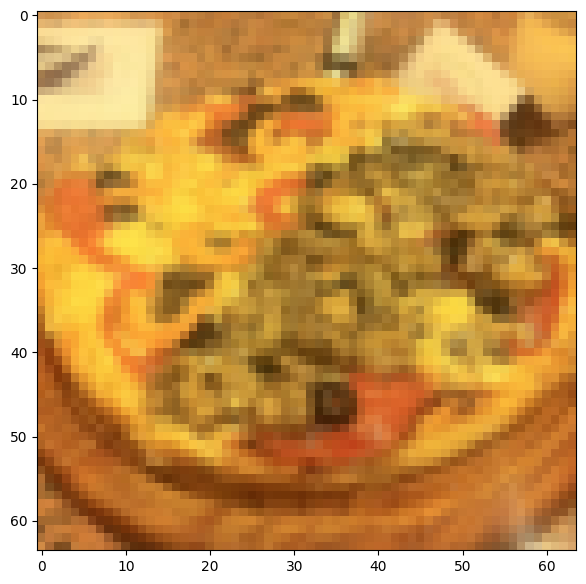

In [ ]:
img_batch, lbl_batch = train_data[0][0], train_data[0][1]
permuted = img_batch.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

img_batch.shape, permuted.shape, lbl_batch, class_names[lbl_batch]

In [ ]:
def display_random_images(dataset,classes,n=10,display_shape=True,seed=None):
  n = min(n,max(10,n))
  if seed:
    random.seed(seed)

  rnd_idxs = random.sample(range(len(dataset)),k=n)

  plt.figure(figsize=(8,16))

  for i, idx in enumerate(rnd_idxs):
    img, lbl = dataset[idx][0], dataset[idx][1]
    plt.subplot(math.ceil(n/2), 2, i + 1)
    plt.imshow(img.permute(1,2,0))
    plt.axis(False)
    title = ""
    if classes:
      title = f"Class: {classes[lbl]}"
    if display_shape:
      title += f"\nShape: {img.shape}"
    plt.title(title)

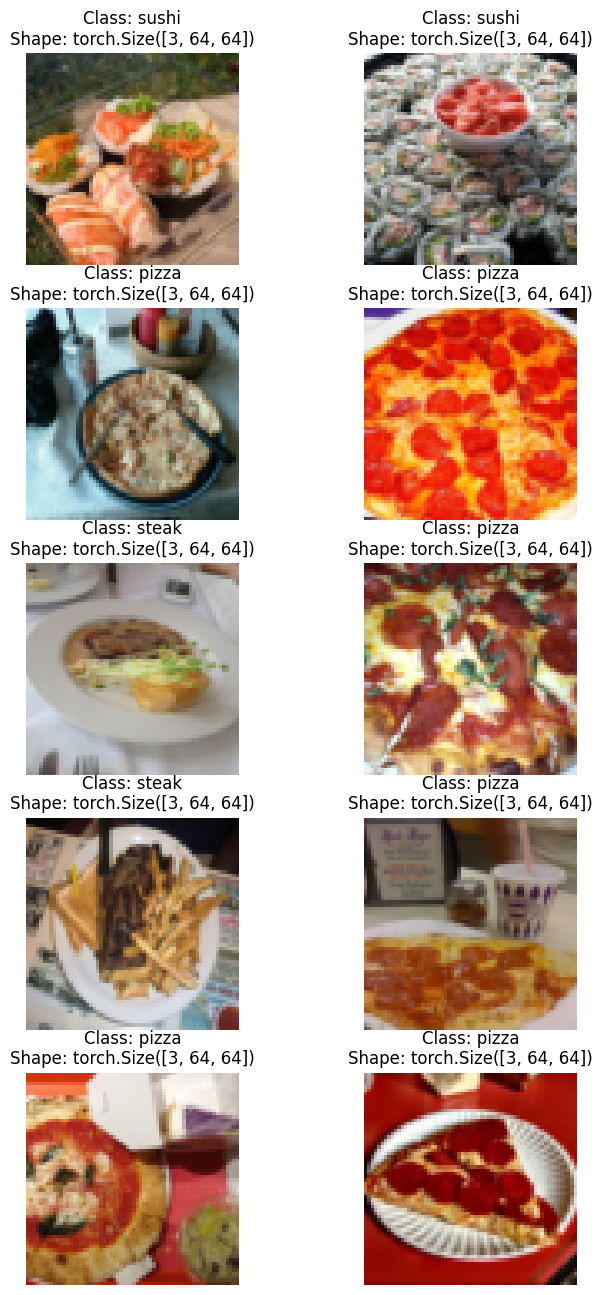

In [ ]:
display_random_images(test_data,class_names)

In [ ]:
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data,batch_size=BATCH_SIZE,num_workers=0,shuffle=True)
test_dataloader = DataLoader(dataset=test_data,batch_size=BATCH_SIZE,num_workers=0,shuffle=False)

In [ ]:
img_batch, lbl_batch = next(iter(train_dataloader))
img_batch.shape, lbl_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

### Data augmentation

In [ ]:
train_transform = transforms.Compose([
  transforms.Resize(size=(224,224)),
  transforms.TrivialAugmentWide(num_magnitude_bins=31),
  transforms.ToTensor(),
])
test_transform = transforms.Compose([
  transforms.Resize(size=(224,224)),
  transforms.ToTensor(),
])

In [ ]:
plot_transformed_images(image_paths,transform=train_transform,n=10)

### TinyVGG

In [ ]:
simple_transform = transforms.Compose([
  transforms.Resize(size=(64,64)),
  transforms.ToTensor(),
])

In [ ]:
train_data = datasets.ImageFolder(
  root=train_dir,
  transform=simple_transform,
)
test_data = datasets.ImageFolder(
  root=test_dir,
  transform=simple_transform,
)

In [ ]:
BATCH_SIZE = 32
NUM_WORKERS = 0
train_dataloader = DataLoader(
  dataset=train_data,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  shuffle=True
)
test_dataloader = DataLoader(
  dataset=test_data,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  shuffle=False
)

In [ ]:
img_batch, lbl_batch = next(iter(train_dataloader))
img_batch.shape, lbl_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [ ]:
class Model(nn.Module):
  """
  TinyVGG
  """
  def __init__(self,channels,hidden_units,n_classes):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(
          in_channels=channels,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=0,
        ),
        nn.ReLU(),
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=0,
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=0,
        ),
        nn.ReLU(),
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=0,
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*13*13,out_features=n_classes),
    )

  def forward(self,x):
    # print(x.shape)
    # x = self.conv_block_1(x)
    # print(x.shape)
    # x = self.conv_block_2(x)
    # print(x.shape)
    # x = self.classifier(x)
    # print(x.shape)
    # return x
    return self.classifier(self.conv_block_2(self.conv_block_1(x))) # operation fusion

In [ ]:
torch.manual_seed(42)

model = Model(3,10,len(class_names)).to(device)
model

Model(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [ ]:
summary(model,input_size=[32,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [32, 3]                   --
├─Sequential: 1-1                        [32, 10, 30, 30]          --
│    └─Conv2d: 2-1                       [32, 10, 62, 62]          280
│    └─ReLU: 2-2                         [32, 10, 62, 62]          --
│    └─Conv2d: 2-3                       [32, 10, 60, 60]          910
│    └─ReLU: 2-4                         [32, 10, 60, 60]          --
│    └─MaxPool2d: 2-5                    [32, 10, 30, 30]          --
├─Sequential: 1-2                        [32, 10, 13, 13]          --
│    └─Conv2d: 2-6                       [32, 10, 28, 28]          910
│    └─ReLU: 2-7                         [32, 10, 28, 28]          --
│    └─Conv2d: 2-8                       [32, 10, 26, 26]          910
│    └─ReLU: 2-9                         [32, 10, 26, 26]          --
│    └─MaxPool2d: 2-10                   [32, 10, 13, 13]          --
├─Sequentia

In [ ]:
torch.manual_seed(42)
_ = model(img_batch.to(device))

In [ ]:
img_batch.shape[2]//4*img_batch.shape[3]//4*10 # padding=1

2560

In [ ]:
13*13*10 # flatten

1690

In [ ]:
(1690+1)*3 # [weights (a) + b] * sets of weights -> a * x + b

5073

In [ ]:
def train_model(epochs,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device):
  torch.manual_seed(42)

  results = {
    "train_loss":[],
    "train_acc":[],
    "test_loss":[],
    "test_acc":[],
  }

  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = 0, 0

    for batch, (X, y) in enumerate(train_dataloader):
      X, y = X.to(device), y.to(device)
      model.train()
      y_pred = model(X)
      loss = loss_fn(y_pred, y)
      train_loss += loss
      train_acc += accuracy_fn(y_pred.argmax(dim=1),y)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      if batch % 500 == 0:
        print(f"Batch: {batch} Samples: {batch*len(X)}/{len(train_dataloader.dataset)}")

    print(f"Batch: {batch} Samples: {batch*len(X)}/{len(train_dataloader.dataset)}")

    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)

    test_loss, test_acc = 0, 0
    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_dataloader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        test_pred = model(X_test)
        test_loss += loss_fn(test_pred,y_test)
        test_acc += accuracy_fn(test_pred.argmax(dim=1),y_test)

      test_loss /= len(test_dataloader)
      test_acc /= len(test_dataloader)

    print(f"Epoch: {epoch} Train loss: {train_loss:.4f} Train acc: {train_acc:.4f} Test loss: {test_loss:.4f} Test acc: {test_acc:.4f}\n")

    results["train_loss"].append(train_loss.detach())
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

  return results

In [ ]:
def eval_model(model,data_loader,loss_fn,accuracy_fn):
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:
      X, y = X.to(device), y.to(device)
      y_pred = model(X)
      loss += loss_fn(y_pred,y)
      acc += accuracy_fn(y_pred.argmax(dim=1),y)
    loss /= len(data_loader)
    acc /= len(data_loader)
  return {"model_name": model.__class__.__name__, "model_loss": loss.item(), "model_acc": acc.item()}

In [ ]:
loss_fn = nn.CrossEntropyLoss() # multi-class data
optimizer = torch.optim.Adam(params=model.parameters(),lr=0.001)
accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

In [ ]:
%%time
results_0 = train_model(15,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device)
results_0

  0%|          | 0/15 [00:00<?, ?it/s]

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 0 Train loss: 1.1016 Train acc: 0.3104 Test loss: 1.0993 Test acc: 0.2875

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 1 Train loss: 1.0902 Train acc: 0.3875 Test loss: 1.0695 Test acc: 0.3875

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 2 Train loss: 1.0564 Train acc: 0.4625 Test loss: 0.9945 Test acc: 0.4682

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 3 Train loss: 0.9356 Train acc: 0.5500 Test loss: 0.9823 Test acc: 0.5375

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 4 Train loss: 0.9029 Train acc: 0.5604 Test loss: 0.9755 Test acc: 0.4494

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 5 Train loss: 0.8952 Train acc: 0.5896 Test loss: 0.9249 Test acc: 0.4943

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 6 Train loss: 0.8548 Train acc: 0.6104 Test loss: 0.9432 Test acc: 0.5432

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 7 Train loss: 0.850

{'train_loss': [tensor(1.1016, device='cuda:0'),
  tensor(1.0902, device='cuda:0'),
  tensor(1.0564, device='cuda:0'),
  tensor(0.9356, device='cuda:0'),
  tensor(0.9029, device='cuda:0'),
  tensor(0.8952, device='cuda:0'),
  tensor(0.8548, device='cuda:0'),
  tensor(0.8501, device='cuda:0'),
  tensor(0.8428, device='cuda:0'),
  tensor(0.8393, device='cuda:0'),
  tensor(0.8419, device='cuda:0'),
  tensor(0.8434, device='cuda:0'),
  tensor(0.8726, device='cuda:0'),
  tensor(0.8212, device='cuda:0'),
  tensor(0.8208, device='cuda:0')],
 'train_acc': [tensor(0.3104, device='cuda:0'),
  tensor(0.3875, device='cuda:0'),
  tensor(0.4625, device='cuda:0'),
  tensor(0.5500, device='cuda:0'),
  tensor(0.5604, device='cuda:0'),
  tensor(0.5896, device='cuda:0'),
  tensor(0.6104, device='cuda:0'),
  tensor(0.5854, device='cuda:0'),
  tensor(0.6396, device='cuda:0'),
  tensor(0.6000, device='cuda:0'),
  tensor(0.6229, device='cuda:0'),
  tensor(0.6500, device='cuda:0'),
  tensor(0.6125, device='cu

In [ ]:
eval_model(model,test_dataloader,loss_fn,accuracy_fn)

{'model_name': 'Model',
 'model_loss': 0.9725828170776367,
 'model_acc': 0.48693180084228516}

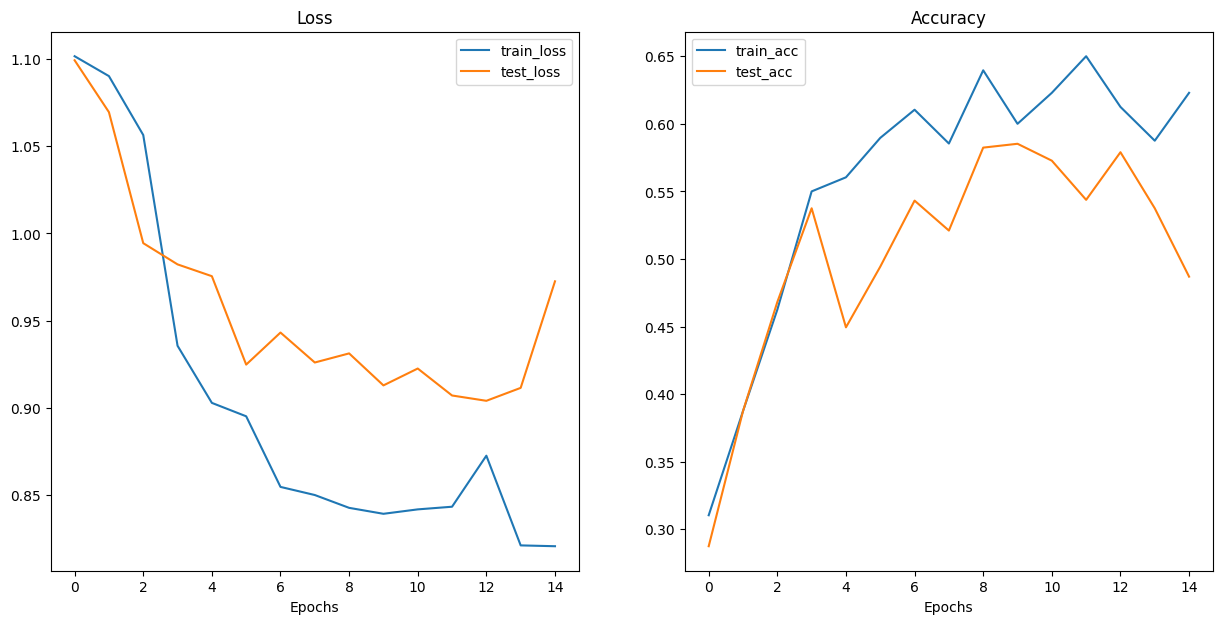

In [ ]:
def plot_loss_curves(results):
    results = {k: torch.stack(v).cpu().numpy() for k, v in results.items()}
    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(15,7))

    plt.subplot(1,2,1)
    plt.plot(epochs,results["train_loss"],label="train_loss")
    plt.plot(epochs,results["test_loss"],label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs,results["train_acc"],label="train_acc")
    plt.plot(epochs,results["test_acc"],label="test_acc")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

plot_loss_curves(results_0)


Loss curves:
* Underfitting: the loss can be lower
* Overfitting: the train loss is lower than the test loss
* Just right: train and test losses are similar and go down the same way

Overfitting:
- get more data
- data augmentation
- better data
- transfer learning
- simplify the model
- learning rate decay
- early stopping

Underfitting:
- add more layers to the model
- tweak the learning rate
- train for longer
- transfer learning
- less regularization

### Data augmentation

In [ ]:
train_data = datasets.ImageFolder(
  root=train_dir,
  transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor(),
  ]),
)
test_data = datasets.ImageFolder(
  root=test_dir,
  transform=simple_transform,
)

In [ ]:
BATCH_SIZE = 32
NUM_WORKERS = 0
train_dataloader = DataLoader(
  dataset=train_data,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  shuffle=True
)
test_dataloader = DataLoader(
  dataset=test_data,
  batch_size=BATCH_SIZE,
  num_workers=NUM_WORKERS,
  shuffle=False
)

In [ ]:
torch.manual_seed(42)

model = Model(3,10,len(class_names)).to(device)
model

Model(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1690, out_features=3, bias=True)
  )
)

In [ ]:
loss_fn = nn.CrossEntropyLoss() # multi-class data
optimizer = torch.optim.Adam(params=model.parameters(),lr=0.001)
accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

In [ ]:
%%time
results_1 = train_model(15,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device)
results_1

  0%|          | 0/15 [00:00<?, ?it/s]

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 0 Train loss: 1.1026 Train acc: 0.3125 Test loss: 1.1018 Test acc: 0.2875

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 1 Train loss: 1.0943 Train acc: 0.3521 Test loss: 1.0876 Test acc: 0.4000

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 2 Train loss: 1.0797 Train acc: 0.3958 Test loss: 1.0629 Test acc: 0.3778

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 3 Train loss: 1.0389 Train acc: 0.4479 Test loss: 0.9709 Test acc: 0.5636

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 4 Train loss: 1.0051 Train acc: 0.4563 Test loss: 1.0188 Test acc: 0.4545

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 5 Train loss: 1.0193 Train acc: 0.5083 Test loss: 0.9673 Test acc: 0.5795

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 6 Train loss: 1.0210 Train acc: 0.4521 Test loss: 0.9477 Test acc: 0.4688

Batch: 0 Samples: 0/450
Batch: 14 Samples: 28/450
Epoch: 7 Train loss: 0.963

{'train_loss': [tensor(1.1026, device='cuda:0'),
  tensor(1.0943, device='cuda:0'),
  tensor(1.0797, device='cuda:0'),
  tensor(1.0389, device='cuda:0'),
  tensor(1.0051, device='cuda:0'),
  tensor(1.0193, device='cuda:0'),
  tensor(1.0210, device='cuda:0'),
  tensor(0.9634, device='cuda:0'),
  tensor(0.9122, device='cuda:0'),
  tensor(1.0021, device='cuda:0'),
  tensor(1.0219, device='cuda:0'),
  tensor(0.9590, device='cuda:0'),
  tensor(0.9618, device='cuda:0'),
  tensor(0.9539, device='cuda:0'),
  tensor(0.9880, device='cuda:0')],
 'train_acc': [tensor(0.3125, device='cuda:0'),
  tensor(0.3521, device='cuda:0'),
  tensor(0.3958, device='cuda:0'),
  tensor(0.4479, device='cuda:0'),
  tensor(0.4563, device='cuda:0'),
  tensor(0.5083, device='cuda:0'),
  tensor(0.4521, device='cuda:0'),
  tensor(0.5563, device='cuda:0'),
  tensor(0.5563, device='cuda:0'),
  tensor(0.5000, device='cuda:0'),
  tensor(0.4500, device='cuda:0'),
  tensor(0.5542, device='cuda:0'),
  tensor(0.5312, device='cu

In [ ]:
eval_model(model,test_dataloader,loss_fn,accuracy_fn)

{'model_name': 'Model',
 'model_loss': 0.9245894551277161,
 'model_acc': 0.5727273225784302}

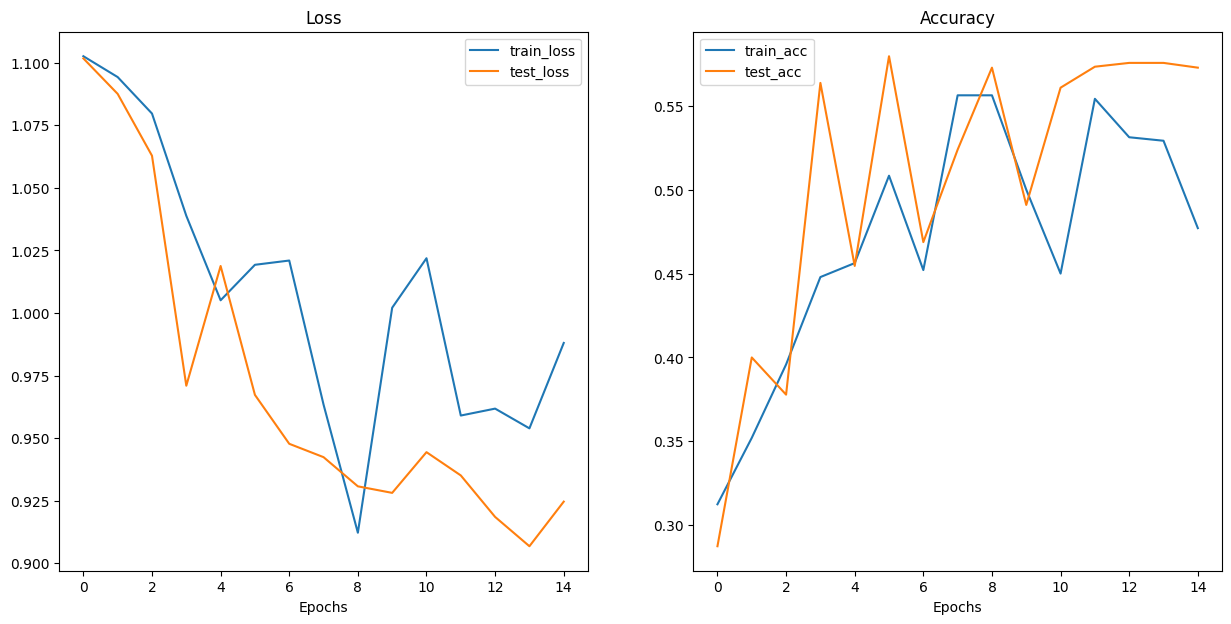

In [ ]:
plot_loss_curves(results_1)

## Compare model results

- manual
- tensorboard
- weights & biases
- mlflow

In [ ]:
results_0_df = pd.DataFrame({k: torch.stack(v).cpu().numpy() for k, v in results_0.items()})
results_1_df = pd.DataFrame({k: torch.stack(v).cpu().numpy() for k, v in results_1.items()})

In [ ]:
results_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.101589,0.310417,1.099266,0.287500
1,1.090193,0.387500,1.069537,0.387500
2,1.056428,0.462500,0.994454,0.468182
3,0.935650,0.550000,0.982290,0.537500
4,0.902916,0.560417,0.975527,0.449432
5,0.895230,0.589583,0.924855,0.494318
6,0.854762,0.610417,0.943221,0.543182
7,0.850110,0.585417,0.926057,0.521023
8,0.842759,0.639583,0.931277,0.582386
9,0.839350,0.600000,0.912939,0.585227


In [ ]:
results_1_df

,train_loss,train_acc,test_loss,test_acc
0,1.102645,0.312500,1.101773,0.287500
1,1.094306,0.352083,1.087585,0.400000
2,1.079730,0.395833,1.062868,0.377841
3,1.038855,0.447917,0.970926,0.563636
4,1.005080,0.456250,1.018786,0.454545
5,1.019264,0.508333,0.967261,0.579545
6,1.020968,0.452083,0.947709,0.468750
7,0.963372,0.556250,0.942365,0.523864
8,0.912152,0.556250,0.930704,0.572727
9,1.002099,0.500000,0.928088,0.490909


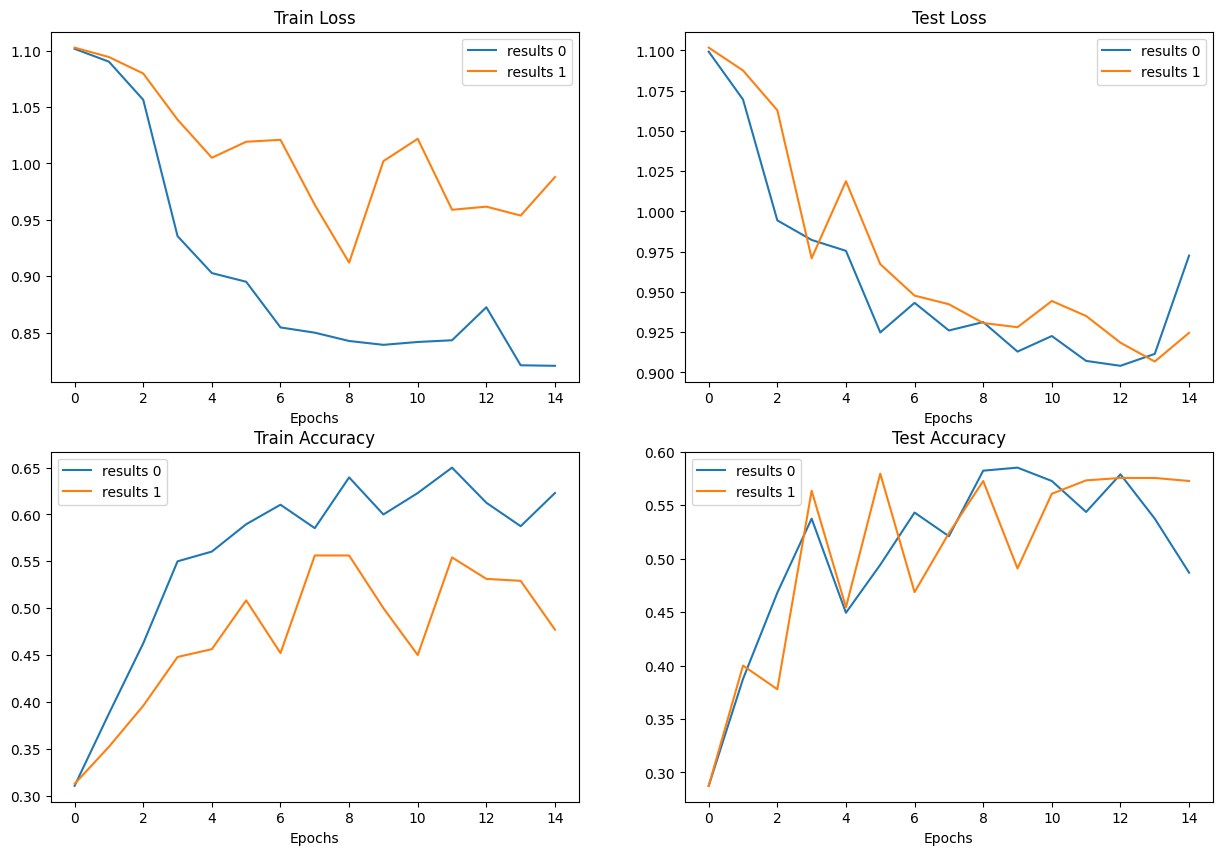

In [ ]:
plt.figure(figsize=(15,10))
epochs = range(len(results_0_df))

plt.subplot(2,2,1)
plt.plot(epochs,results_0_df['train_loss'],label="results 0")
plt.plot(epochs,results_1_df['train_loss'],label="results 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

plt.subplot(2,2,2)
plt.plot(epochs,results_0_df['test_loss'],label="results 0")
plt.plot(epochs,results_1_df['test_loss'],label="results 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

plt.subplot(2,2,3)
plt.plot(epochs,results_0_df['train_acc'],label="results 0")
plt.plot(epochs,results_1_df['train_acc'],label="results 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

plt.subplot(2,2,4)
plt.plot(epochs,results_0_df['test_acc'],label="results 0")
plt.plot(epochs,results_1_df['test_acc'],label="results 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend()

In [ ]:
custom_image_path = data_dir / "pizza.jpg"

if not custom_image_path.exists():
  with open(custom_image_path, "wb") as f:
    res = requests.get("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSJfriuI0wpzeTFk3k5fZIWDS1HcAPsNaugpRTGYVaTTg&s=10")
    f.write(res.content)

custom_image_path.exists()

True

(554, 554, 3)

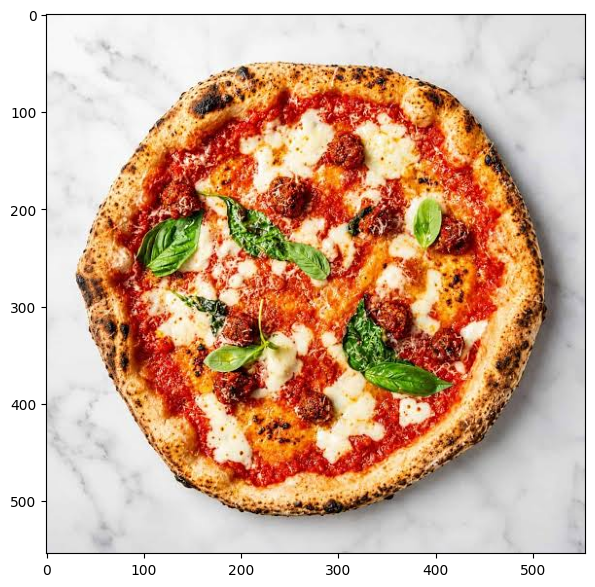

In [ ]:
img = Image.open(custom_image_path)

img_arr = np.asarray(img)
plt.figure(figsize=(10,7))
plt.imshow(img_arr)
img_arr.shape

torch.Size([64, 64, 3])

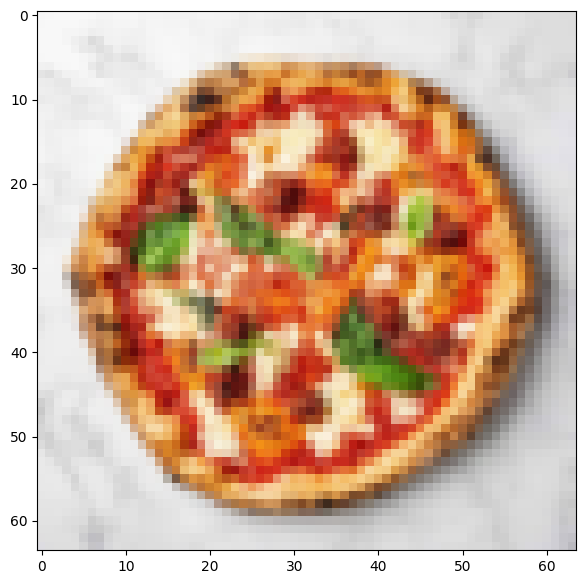

In [ ]:
simple_transform = transforms.Compose([
  transforms.Resize(size=(64,64)),
  transforms.ToTensor()
])
tensor = simple_transform(img).to(device)

permuted = tensor.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

permuted.shape

In [ ]:
model.eval()
with torch.inference_mode():
  pred = model(tensor.unsqueeze(dim=0))
  class_id = pred.argmax(dim=1).item()

class_names[class_id], pred

('pizza', tensor([[ 0.0840, -0.5788, -0.4218]], device='cuda:0'))

In [ ]:
custom_image_path = data_dir / "pizza-steak.jpg"

if not custom_image_path.exists():
  with open(custom_image_path, "wb") as f:
    res = requests.get("https://au.gozney.com/cdn/shop/articles/Philly_Cheesesteak_PIzza_Adam_Purnell__shropshirelad_2.jpg?v=1644241461&width=1500")
    f.write(res.content)

custom_image_path.exists()

True

(844, 1500, 3)

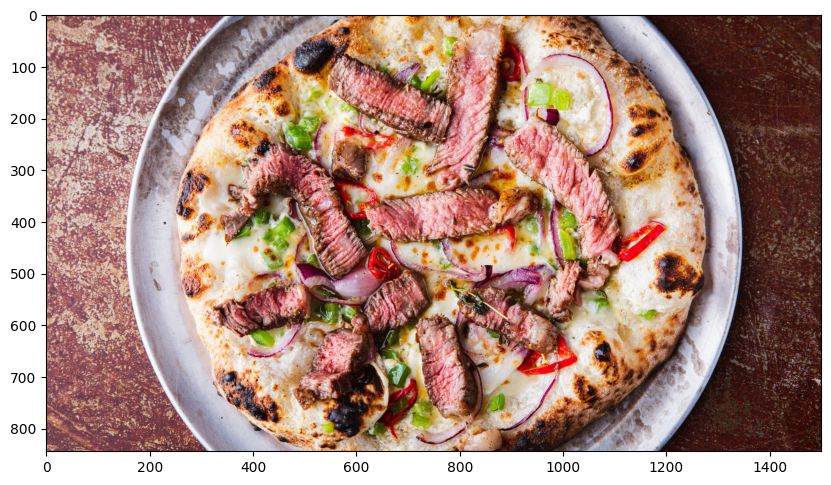

In [ ]:
img = Image.open(custom_image_path)

img_arr = np.asarray(img)
plt.figure(figsize=(10,7))
plt.imshow(img_arr)
img_arr.shape

(torch.Size([844, 1500, 3]), torch.float32)

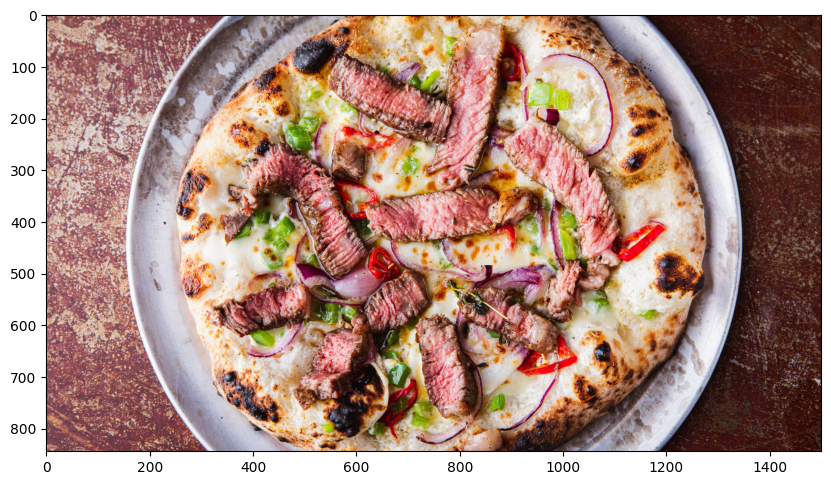

In [ ]:
tensor = torchvision.io.read_image(custom_image_path).to(device).type(torch.float) / 255

permuted = tensor.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

permuted.shape, tensor.dtype

(torch.Size([64, 64, 3]), torch.float32)

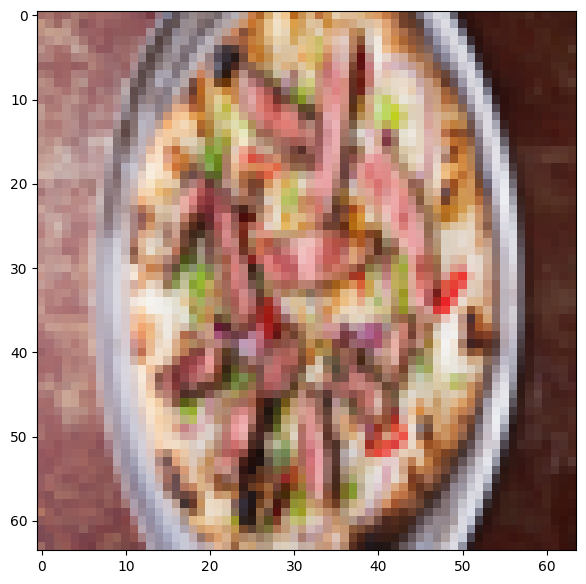

In [ ]:
simple_transform = transforms.Compose([
  transforms.Resize(size=(64,64)),
])
tensor = simple_transform(tensor).to(device)

permuted = tensor.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

permuted.shape, tensor.dtype

In [ ]:
model.eval()
with torch.inference_mode():
  pred = model(tensor.unsqueeze(dim=0))
  class_id = pred.argmax(dim=1).item()

class_names[class_id], pred

('pizza', tensor([[ 0.2556, -0.8891, -0.1525]], device='cuda:0'))

('sushi',
 tensor([[-0.0861, -0.8700,  0.1799]], device='cuda:0'),
 tensor([[0.3621, 0.1654, 0.4725]], device='cuda:0'))

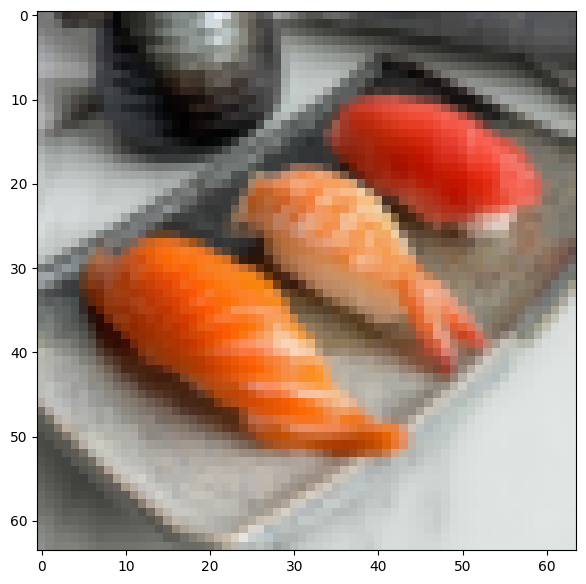

In [ ]:
res = requests.get("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTWkIW9HAV5rFJtWb3BjSZP1g5Amt7oWJ4vdFyaU0CVNjNxDlbwiK7P9d2r&s=10")
data = torch.frombuffer(bytearray(res.content), dtype=torch.uint8)
tensor = torchvision.io.decode_image(data, mode=torchvision.io.ImageReadMode.RGB)
tensor = tensor.to(device).type(torch.float) / 255   # [3, H, W], values in [0, 1]

simple_transform = transforms.Compose([
  transforms.Resize(size=(64,64)),
])
tensor = simple_transform(tensor)

permuted = tensor.permute(1, 2, 0)
plt.figure(figsize=(10,7))
plt.imshow(permuted.cpu().numpy())

model.eval()
with torch.inference_mode():
  pred = model(tensor.unsqueeze(dim=0))
  probs = pred.softmax(dim=1)
  class_id = pred.argmax(dim=1).item()

class_names[class_id], pred, probs